In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [43]:
df = pd.read_parquet("4FLG_Procesado.parquet")
df

,CLASS1,BlazarDist,Variability_Index,Frac_Variability,SpectrumType_LogParabola,SpectrumType_PowerLaw,SpectrumType_PLSuperExpCutoff,Energy_Flux100,LP_Index,LP_SigCurv,PL_Index,Pivot_Energy,Flux_Band_0,Flux_Band_4,Flux_Band_6,Flux_Band_7,nuFnu_Band_0,nuFnu_Band_4,nuFnu_Band_6,nuFnu_Band_7
0,bll,1,51.742390,0.429135,0,1,0,7.807578e-12,2.052470,1.283201,2.081634,2065.146729,1.664147e-12,1.866136e-10,1.364606e-11,1.204809e-12,2.657329e-16,1.268975e-12,9.279336e-13,2.075041e-13
1,bcu,1,25.609457,0.368921,1,0,0,3.260804e-12,1.580971,2.630329,1.781085,2729.530029,1.858900e-10,9.661182e-11,1.290118e-11,1.572634e-12,3.136423e-14,6.833589e-13,8.547137e-13,2.149872e-13
2,bcu,1,26.910145,0.937606,0,1,0,8.967048e-13,1.763400,0.958782,1.906426,4281.748047,3.287979e-11,2.881598e-11,4.228593e-16,1.748820e-12,5.286959e-15,2.000432e-13,2.935529e-17,3.234954e-13
3,bll,1,10.370596,0.000000,1,0,0,2.441939e-12,1.599259,3.092949,1.817964,3402.819092,4.485441e-09,6.530654e-11,5.156945e-12,4.613763e-17,7.668804e-13,4.618040e-13,3.346412e-13,5.758958e-18
4,other,0,7.720544,0.000000,1,0,0,4.373159e-12,2.641635,3.182654,2.518880,1996.203979,9.472302e-14,6.726024e-11,3.627743e-16,1.618911e-16,1.578786e-17,4.073829e-13,1.990180e-17,1.499963e-17
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2912,bcu,1,18.010399,0.259739,1,0,0,1.354165e-12,1.577917,3.787348,1.752499,5153.450684,6.129970e-12,4.413272e-11,1.857165e-12,5.640288e-17,1.062581e-15,3.169375e-13,1.105479e-13,5.420474e-18
2913,bll,1,14.498226,0.068273,0,1,0,4.093997e-12,1.924309,0.000000,1.928476,2930.842285,4.975796e-09,8.682364e-11,1.378831e-11,1.948438e-12,7.993894e-13,6.011633e-13,9.546973e-13,3.571405e-13
2914,bcu,1,6.934350,0.000000,1,0,0,1.116031e-12,2.639918,3.037318,2.714450,717.048584,2.112895e-08,4.710498e-12,8.963529e-15,3.741380e-15,3.582740e-12,2.547993e-14,4.679423e-16,3.466486e-16
2915,bcu,1,8.082824,0.000000,1,0,0,1.752340e-12,1.904424,2.774415,2.094933,1490.850708,8.510176e-14,6.003090e-11,1.787903e-12,1.558835e-19,1.431744e-17,3.939935e-13,1.071259e-13,1.637076e-20


In [44]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler

In [45]:
#Preparación y escalamiento de datos para el modelo de clasificación
X = df.drop(columns=["CLASS1", "BlazarDist"])
y = df["BlazarDist"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [46]:
#Entrenar y evaluar modelo
classifier = RandomForestClassifier(n_estimators=200, max_depth=10)
classifier.fit(X_train, y_train)

y_pred = classifier.predict(X_test)

Accuracy: 0.940068493150685
f1-score: 0.937469772615451
Confussion Matrix:


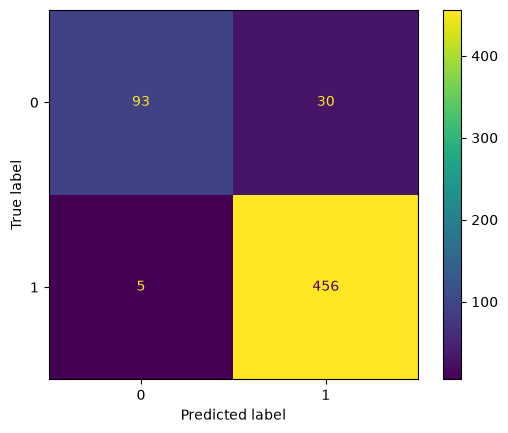

In [47]:
print("Accuracy:", metrics.accuracy_score(y_test, y_pred))
print("f1-score:", metrics.f1_score(y_test, y_pred, average='weighted'))

print("Confussion Matrix:")
cm_mlp = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_mlp, display_labels=classifier.classes_)
disp.plot()